In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', None)

In [2]:
# Convert pq to csv
filename = Path("Datasets/LMS_2013-01-01_2026-03-24_HALF_HOUR_au.pq")
df = pd.read_parquet(filename, engine='fastparquet')
#df.to_parquet('Datasets/LMS_2013-01-01_2026-03-24_HALF_HOUR_au.pq', index=False)

In [3]:
#filename = 'Datasets/LMS_2013-01-01_2026-03-24_HALF_HOUR_au.pq'
#df = pd.read_csv(filename)
df.head()

,date,6102000812 consumption,6102002302 consumption,6102005454 consumption,6102005592 consumption,6102009742 consumption,6102009743 consumption,6102009744 consumption,6102023971 consumption,6102038376 consumption,...,VAAA003176 consumption,VAAA003194 consumption,VAAA003197 consumption,VAAA003225 consumption,VAAA003429 consumption,VAAA004066 consumption,VCCCAE0035 consumption,VCCCBC0096 consumption,VCCCSC0045 consumption,VCCCSD0058 consumption
0,2013-01-01 00:00:00,20.768,11.659,24.76,17.92,5.232,18.735,13.199,204.30,70.84,...,16.74,19.76,28.20,6.932,0.0,0.0,95.968,23.490,9.320,21.087
1,2013-01-01 00:30:00,20.512,11.260,24.64,18.52,5.376,18.700,13.020,207.66,70.56,...,17.76,19.82,28.72,6.842,0.0,0.0,96.512,23.865,9.072,19.296
2,2013-01-01 01:00:00,20.544,11.459,24.92,18.20,4.720,18.644,13.620,205.68,69.52,...,17.46,19.68,28.60,7.423,0.0,0.0,95.423,24.165,9.080,19.904
3,2013-01-01 01:30:00,20.688,11.419,24.56,17.72,3.582,17.130,13.260,202.32,70.12,...,17.10,19.76,28.26,6.878,0.0,0.0,98.783,22.380,9.072,19.552
4,2013-01-01 02:00:00,22.032,11.340,24.64,18.92,3.952,17.155,12.899,206.82,92.72,...,18.00,19.74,27.70,6.708,0.0,0.0,98.016,22.995,9.216,20.032


In [4]:
# Check for null values
df.isna().sum().sum()

np.int64(0)

In [5]:
# Remove 2020-2022
df["date"] = pd.to_datetime(df["date"])
print("Original length: " + str(len(df)))
df = df[(df['date'].dt.year < 2020) | (df['date'].dt.year > 2022)]
print("New length: "  + str(len(df)))

Original length: 231840
New length: 179232


In [6]:
# Remove NMIs 6102507141 and VAAA003225
print("Original number of NMIs: " + str(len(df.columns)-1))
df.drop(columns=["6102507141 consumption","VAAA003225 consumption"], inplace=True)
print("New number of NMIs: "  + str(len(df.columns)-1))

Original number of NMIs: 101
New number of NMIs: 99


In [10]:
# Check summary statistics
df.describe()

,date,6102000812 consumption,6102002302 consumption,6102005454 consumption,6102005592 consumption,6102009742 consumption,6102009743 consumption,6102009744 consumption,6102023971 consumption,6102038376 consumption,...,VAAA003100 consumption,VAAA003176 consumption,VAAA003194 consumption,VAAA003197 consumption,VAAA003429 consumption,VAAA004066 consumption,VCCCAE0035 consumption,VCCCBC0096 consumption,VCCCSC0045 consumption,VCCCSD0058 consumption
count,179232,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.00000,179232.000000,...,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000
mean,2019-01-22 18:07:10.476700,29.348371,20.379335,69.414515,59.238620,6.777711,60.038581,51.163337,359.68543,81.616330,...,126.081566,37.473407,43.314281,82.122908,2.398839,0.040878,124.688791,28.746126,28.398465,32.133701
min,2013-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015-07-23 11:52:30,21.696000,10.660000,55.160000,18.320000,5.535000,27.303750,20.580000,294.47900,65.520000,...,33.684500,20.159000,29.360000,44.760000,0.000000,0.000000,108.319000,23.220000,14.624000,22.272000
50%,2018-02-10 23:45:00,28.063000,12.659000,65.600000,49.327500,6.512000,36.107500,27.840000,353.50000,78.080000,...,97.989000,25.080000,36.460000,72.720000,0.000000,0.000000,124.576000,28.815000,24.888000,29.792000
75%,2023-09-02 11:37:30,34.815000,26.639000,79.600000,81.054250,7.824000,100.444000,88.920000,410.70000,94.800000,...,218.939750,58.319000,54.960000,115.199000,2.240000,0.000000,139.840000,34.980000,39.520000,40.320000
max,2026-03-23 23:30:00,90.816000,113.759000,135.480000,372.240000,16.672000,258.011000,242.460000,681.80000,258.599000,...,418.296000,135.300000,205.000000,265.380000,25.024000,14.192000,322.208000,89.205000,118.336000,123.936000
std,NaN,10.181579,15.598332,18.681308,50.848458,1.678713,41.586852,39.281036,74.77068,24.398325,...,94.898368,22.938596,18.850291,45.680746,4.388804,0.146747,31.757127,10.367940,17.278949,16.789790


In [20]:
# Check first date of energy consumption
# Check if there are 0s after first consumption
first_dates = {}
last_dates = {}
zeroConsumption = {}
percentZeroConsumption = {}
describe_df = {}
NMI_list = df.columns.tolist()[1:]
for col in NMI_list:
    first_date = min(df[df[col]>0]['date'])
    last_date = max(df[df[col]>0]['date'])
    filtered_col = df[(df['date']>=first_date) & (df['date']<=last_date)][['date',col]]
    
    zeroConsumption[col.split(' ')[0]] = len(filtered_col[col]==0)
    percentZeroConsumption[col.split(' ')[0]] = zeroConsumption[col.split(' ')[0]] / len(filtered_col)
    first_dates[col.split(' ')[0]] = first_date
    last_dates[col.split(' ')[0]] = last_date

    describe_df[col.split(' ')[0]] = filtered_col[col].describe()

In [21]:
checkdf = pd.DataFrame([first_dates,last_dates,zeroConsumption,percentZeroConsumption]).transpose().reset_index(drop=False)
checkdf.columns = ['NMI','first consumption','last consumption','zeroes after first consumption','% of zeroes after first consumption']
checkdf.sort_values(by='zeroes after first consumption', ascending=False, inplace=True, ignore_index=True)
checkdf

,NMI,first consumption,last consumption,zeroes after first consumption,% of zeroes after first consumption
0,6102000812,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
1,VAAA000450,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
2,6102002302,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
3,VAAA000057,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
4,VAAA000173,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
5,VAAA000175,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
6,VAAA000177,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
7,VAAA000178,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
8,VAAA000180,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0
9,VAAA000181,2013-01-01 00:00:00,2026-03-23 23:30:00,179232,1.0


In [18]:
checkdf.to_csv('first non-zero.csv')

In [10]:
# Check summary statistics
df.describe()

,date,6102000812 consumption,6102002302 consumption,6102005454 consumption,6102005592 consumption,6102009742 consumption,6102009743 consumption,6102009744 consumption,6102023971 consumption,6102038376 consumption,...,VAAA003100 consumption,VAAA003176 consumption,VAAA003194 consumption,VAAA003197 consumption,VAAA003429 consumption,VAAA004066 consumption,VCCCAE0035 consumption,VCCCBC0096 consumption,VCCCSC0045 consumption,VCCCSD0058 consumption
count,179232,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.00000,179232.000000,...,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000,179232.000000
mean,2019-01-22 18:07:10.476700,29.348371,20.379335,69.414515,59.238620,6.777711,60.038581,51.163337,359.68543,81.616330,...,126.081566,37.473407,43.314281,82.122908,2.398839,0.040878,124.688791,28.746126,28.398465,32.133701
min,2013-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015-07-23 11:52:30,21.696000,10.660000,55.160000,18.320000,5.535000,27.303750,20.580000,294.47900,65.520000,...,33.684500,20.159000,29.360000,44.760000,0.000000,0.000000,108.319000,23.220000,14.624000,22.272000
50%,2018-02-10 23:45:00,28.063000,12.659000,65.600000,49.327500,6.512000,36.107500,27.840000,353.50000,78.080000,...,97.989000,25.080000,36.460000,72.720000,0.000000,0.000000,124.576000,28.815000,24.888000,29.792000
75%,2023-09-02 11:37:30,34.815000,26.639000,79.600000,81.054250,7.824000,100.444000,88.920000,410.70000,94.800000,...,218.939750,58.319000,54.960000,115.199000,2.240000,0.000000,139.840000,34.980000,39.520000,40.320000
max,2026-03-23 23:30:00,90.816000,113.759000,135.480000,372.240000,16.672000,258.011000,242.460000,681.80000,258.599000,...,418.296000,135.300000,205.000000,265.380000,25.024000,14.192000,322.208000,89.205000,118.336000,123.936000
std,NaN,10.181579,15.598332,18.681308,50.848458,1.678713,41.586852,39.281036,74.77068,24.398325,...,94.898368,22.938596,18.850291,45.680746,4.388804,0.146747,31.757127,10.367940,17.278949,16.789790


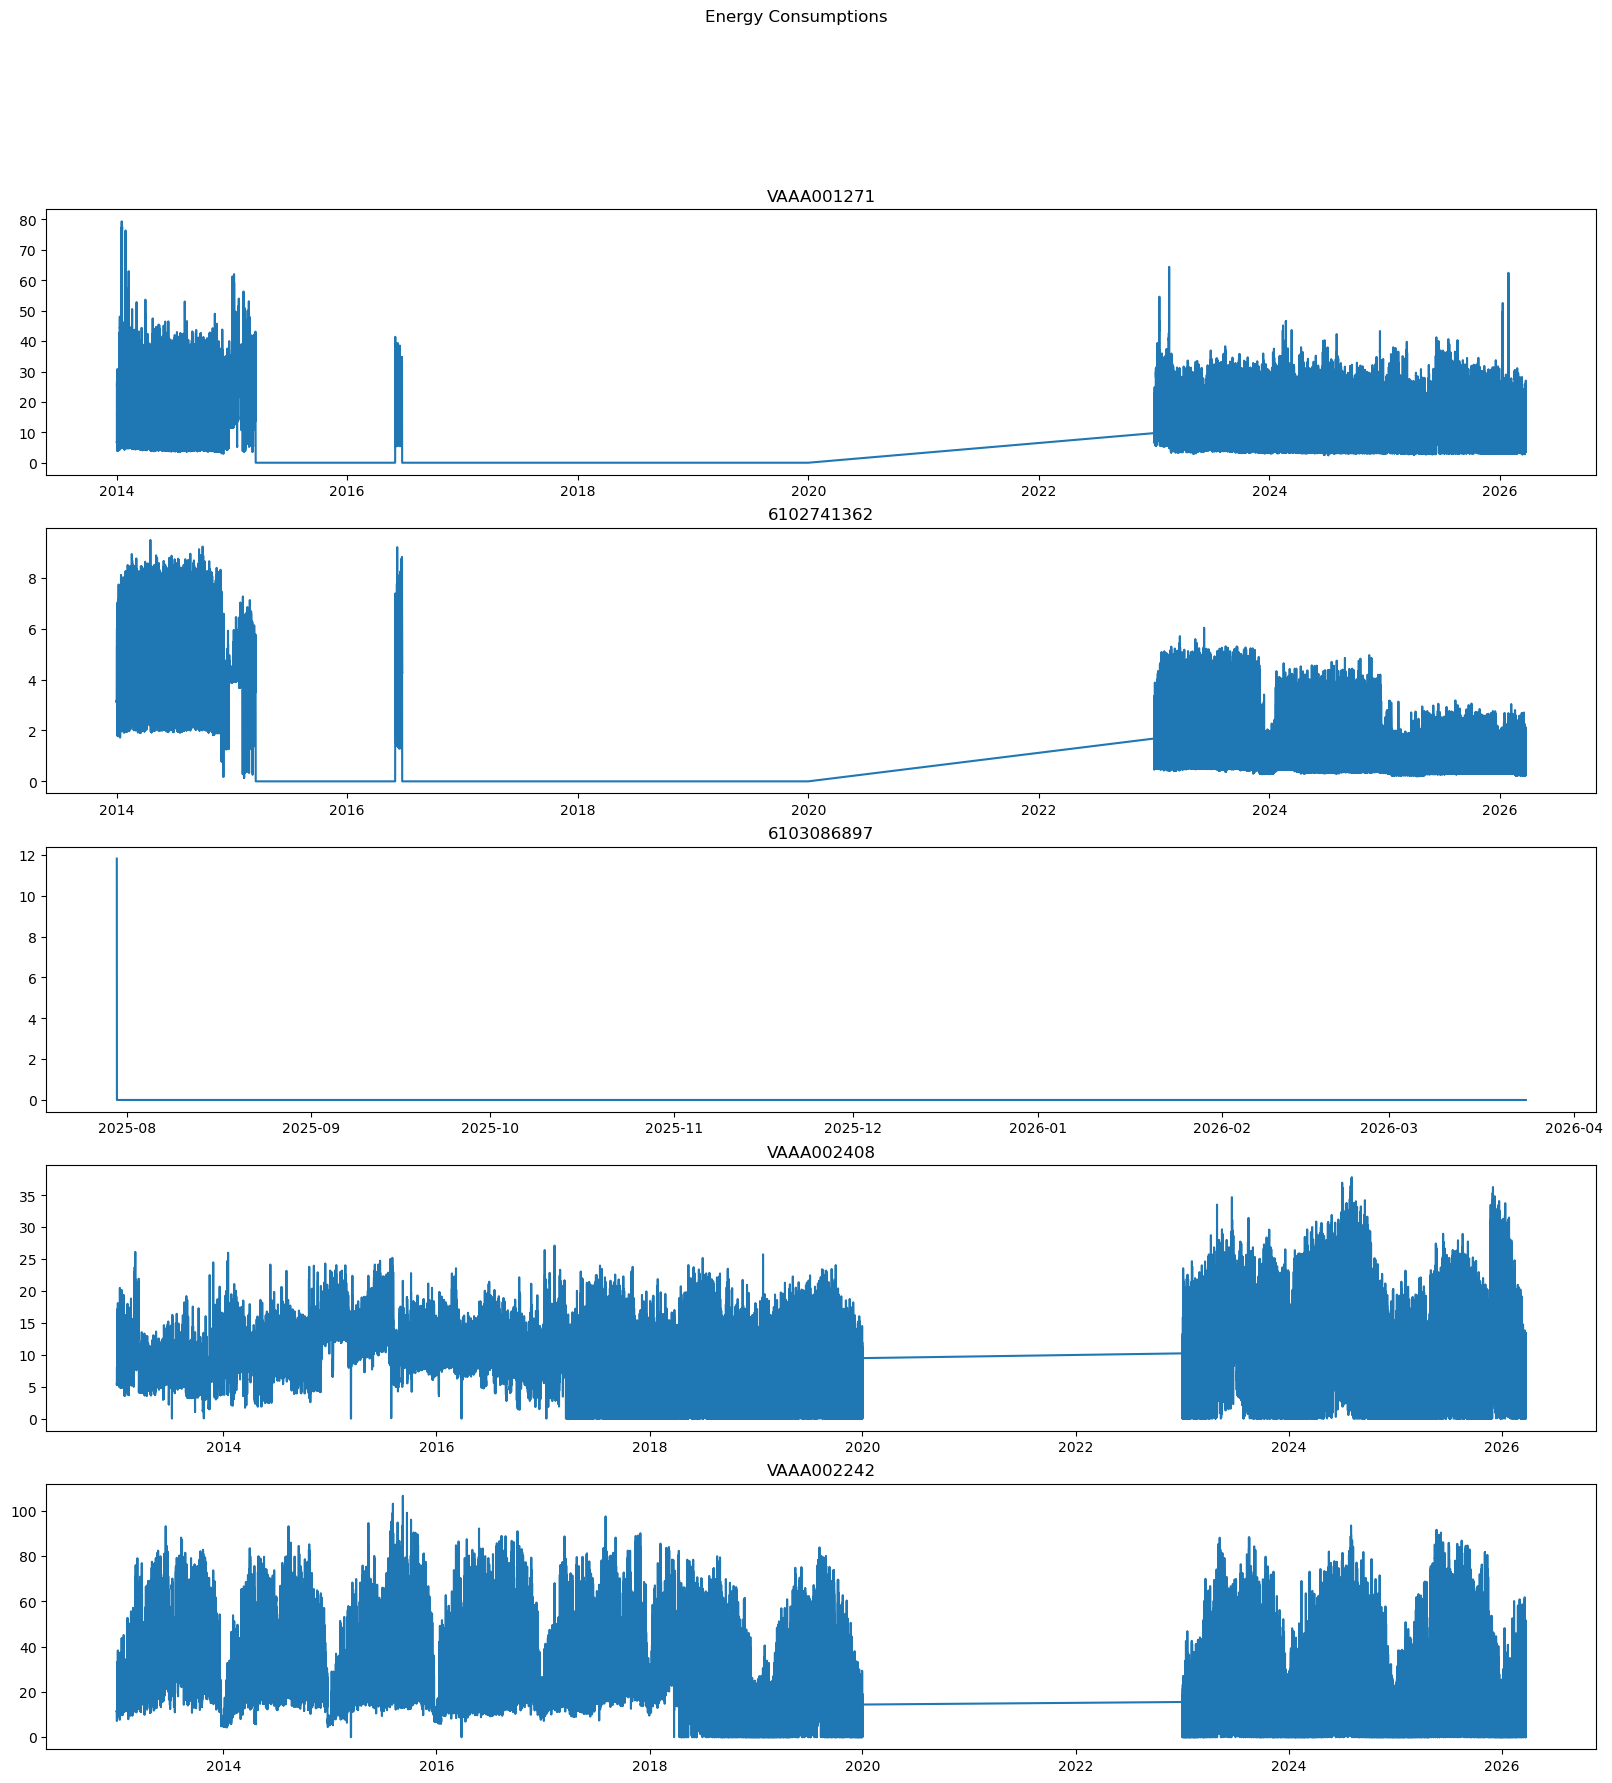

In [9]:
# Plot energy consumption
fig = plt.figure(figsize=(20, 20))
axs = fig.subplots(5)

fig.suptitle('Energy Consumptions')

for i, (nmi,firstdate) in enumerate(zip(checkdf.head(5)['NMI'],checkdf.head(5)['first consumption'])):
    filtered_df = df[df['date']>=firstdate]
    axs[i].plot(filtered_df['date'], filtered_df[nmi + ' consumption'])
    axs[i].set_title(nmi)

plt.show()

In [17]:
# Aggregate to daily
df['day'] = df['date'].dt.date
daily_df = df.pivot_table(index='day', values=NMI_list, aggfunc='sum').reset_index(drop=False)
daily_df

,day,6102000812 consumption,6102002302 consumption,6102005454 consumption,6102005592 consumption,6102009742 consumption,6102009743 consumption,6102009744 consumption,6102023971 consumption,6102038376 consumption,...,VAAA003100 consumption,VAAA003176 consumption,VAAA003194 consumption,VAAA003197 consumption,VAAA003429 consumption,VAAA004066 consumption,VCCCAE0035 consumption,VCCCBC0096 consumption,VCCCSC0045 consumption,VCCCSD0058 consumption
0,2013-01-01,974.544,618.735,1379.600,1269.519,220.580,1625.352,1386.580,10685.157,4140.360,...,9097.671,1451.150,910.080,1345.859,0.000,0.000,5447.697,1197.300,1106.832,907.381
1,2013-01-02,1131.152,1027.506,2886.558,2550.559,235.501,2009.416,1735.242,11917.137,4579.280,...,11204.940,1638.342,1788.140,3606.159,0.000,0.000,5778.165,1291.410,1266.064,1062.508
2,2013-01-03,1418.752,1292.942,3119.639,5567.840,227.034,2696.810,2428.361,12809.396,5278.599,...,12904.244,1965.340,2460.460,4186.940,0.000,0.000,7253.330,1506.240,1602.872,1276.815
3,2013-01-04,1671.390,1748.925,3055.560,7525.639,221.600,3447.488,3187.360,13754.219,6414.080,...,14078.202,2506.008,2816.840,3804.498,0.000,0.000,8547.730,1656.870,1971.728,1491.666
4,2013-01-05,1136.448,774.644,1990.200,2087.479,213.422,1131.610,897.344,11528.219,4944.840,...,10305.364,1025.500,2919.016,1505.340,0.000,0.000,6221.261,1291.665,600.224,1476.144
5,2013-01-06,999.359,569.250,2221.039,2336.800,215.426,1061.375,825.216,11001.416,5119.200,...,9983.182,924.156,2802.940,1477.720,0.000,0.000,5860.497,1197.720,514.416,1642.737
6,2013-01-07,1510.319,1518.820,3279.518,6399.800,231.471,3245.179,2959.954,13541.278,5677.679,...,12473.905,2422.966,2430.099,4010.160,0.000,0.000,7212.245,1596.285,2086.504,2214.989
7,2013-01-08,1506.992,1521.585,3341.278,4503.679,244.831,2681.102,2378.321,13450.076,5482.000,...,11325.636,2153.085,2670.999,4221.599,0.000,0.000,6829.899,1540.050,2019.040,2051.859
8,2013-01-09,1321.488,1239.479,3386.879,2902.797,279.521,2510.972,2177.258,12869.816,4595.360,...,11110.182,1692.348,2225.780,4164.060,0.000,0.000,5996.949,1332.135,1272.960,1247.757
9,2013-01-10,1456.176,1340.327,3349.879,3796.159,269.529,2478.090,2154.164,12838.200,4751.599,...,12606.870,1843.185,2347.820,4284.038,0.000,0.000,6351.730,1480.860,1429.704,1150.511


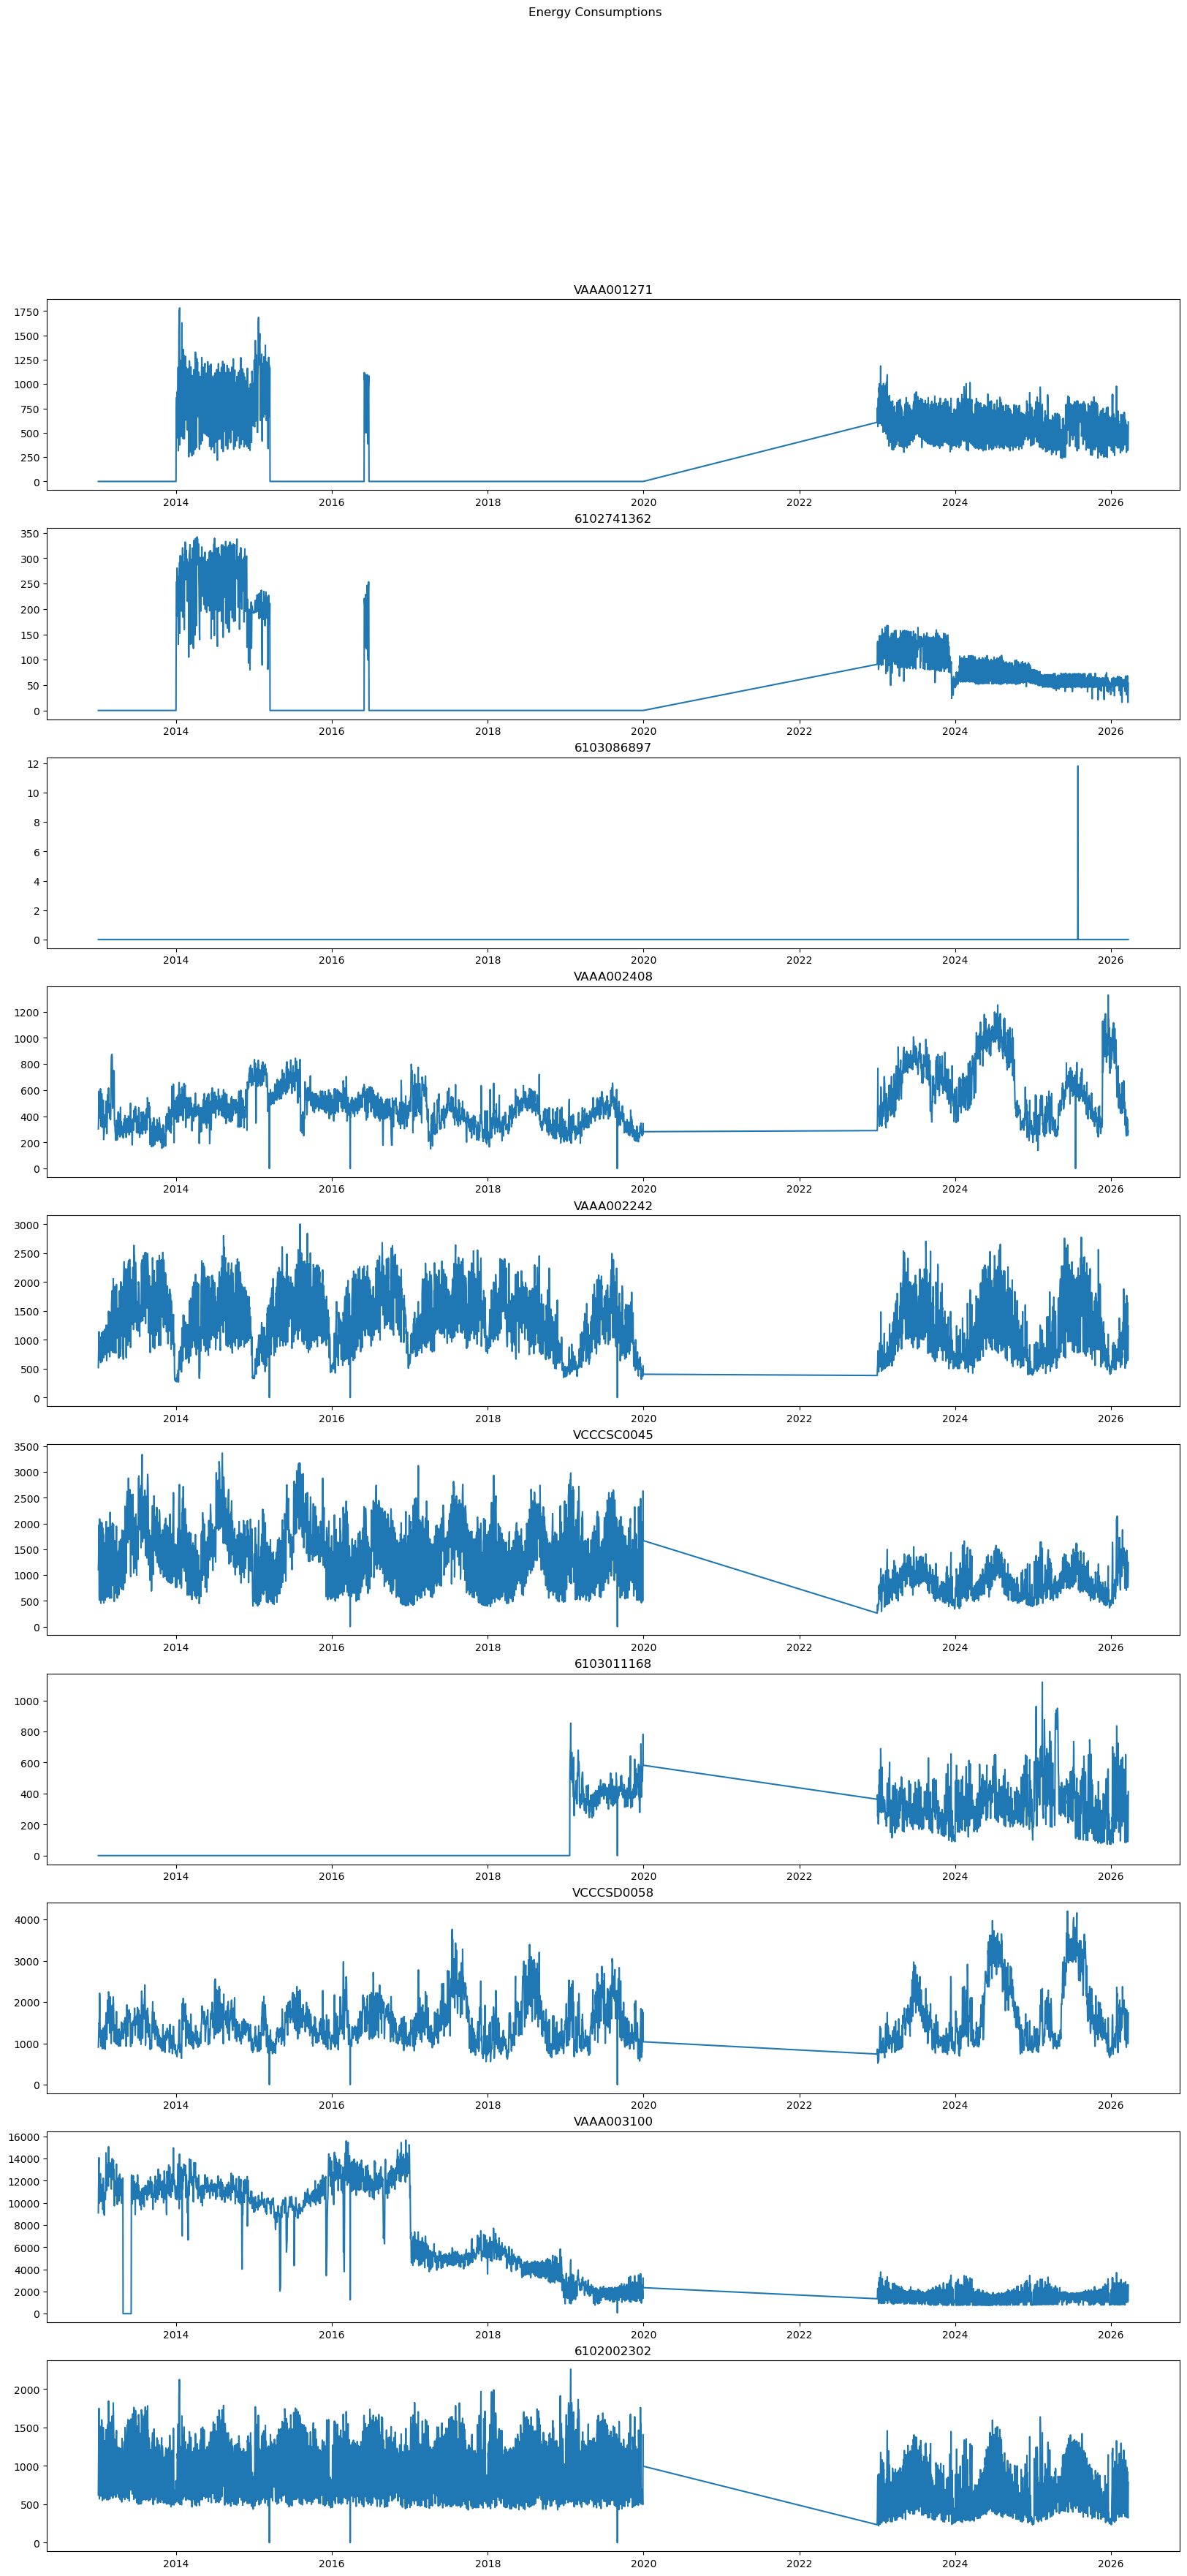

In [32]:
# Plot daily energy consumption
fig = plt.figure(figsize=(20, 40))
axs = fig.subplots(10)

fig.suptitle('Energy Consumptions')

for i, (nmi,firstdate) in enumerate(zip(checkdf.head(10)['NMI'],checkdf.head(10)['first consumption'])):
    axs[i].plot(daily_df['day'], daily_df[nmi + ' consumption'])
    axs[i].set_title(nmi)

plt.show()